#### ***Parallel Workflows***
- ***Non-LLM Workflow (Employee Analytic Tracker)***

In [1]:
import warnings
warnings.filterwarnings("ignore")

from langgraph.graph import StateGraph,START,END 
from typing import TypedDict

# Define State 
class Employee_State(TypedDict):
    employee_name: str
    monthly_salary: int
    working_days: int
    completed_projects: int

    yearly_salary: int
    bonus_amount: int
    project_status: str
    summary: str

In [2]:
# Node_1: calculate yearly salary 
def cal_yearlySalary(state:Employee_State):
    yearly_salary = state["monthly_salary"] * 12 
    return{ 
        'yearly_salary':yearly_salary
    }

# Node_2: Calculate Bonus 
def cal_Bonus(state:Employee_State):
    bonus_amount = state["monthly_salary"] * 2
    return {
        'bonus_amount': bonus_amount
    }

# Node_3: Project Evaluation 
def project_evaluation(state:Employee_State):
    if state['completed_projects'] >=5:
        status = 'Excellent'
    else:
        status = 'Average'
    return {
        'project_status':status
    }

# Summary Node 
def summary(state: Employee_State):
    text = f"""
            ==========================================
                    EMPLOYEE PERFORMANCE REPORT
            ==========================================

            👤 Employee Name   : {state['employee_name']}
            💰 Yearly Salary   : ₹{state['yearly_salary']:,}
            🎁 Bonus Amount    : ₹{state['bonus_amount']:,}
            📊 Project Status  : {state['project_status']}

            ==========================================
        """
    return {
        "summary": text
    }

In [3]:
# Create Graph 
graph = StateGraph(Employee_State)

# Add Node 
graph.add_node('cal_yearlySalary',cal_yearlySalary)
graph.add_node('cal_Bonus',cal_Bonus)
graph.add_node('project_evaluation',project_evaluation)
graph.add_node("generate_summary",summary)

# Add Edges 
graph.add_edge(START, "cal_yearlySalary")
graph.add_edge(START, "cal_Bonus")
graph.add_edge(START, "project_evaluation")

# Merge In
graph.add_edge("cal_yearlySalary", "generate_summary")
graph.add_edge("cal_Bonus", "generate_summary")
graph.add_edge("project_evaluation", "generate_summary")

graph.add_edge("generate_summary", END)

# Compile Workflow 
workflow = graph.compile()

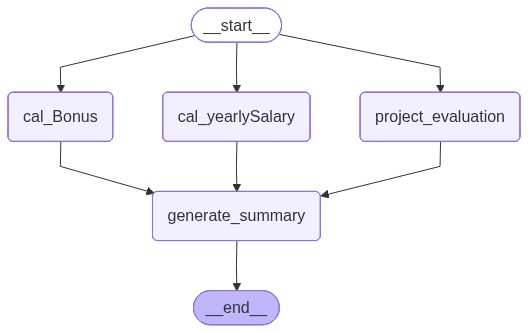

In [4]:
## Visualize Out Graph 
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

In [5]:
## Initial Input

initial_state = {
    'employee_name': 'Ankit',
    'monthly_salary': 500000,
    'working_days': 26,
    'completed_projects': 7
}

## Run Workflow
result = workflow.invoke(initial_state)
print(result["summary"])


                    EMPLOYEE PERFORMANCE REPORT

            👤 Employee Name   : Ankit
            💰 Yearly Salary   : ₹6,000,000
            🎁 Bonus Amount    : ₹1,000,000
            📊 Project Status  : Excellent

        


- ***LLM-Workflow (Essay Evaluatr System)***

In [6]:
from langgraph.graph import StateGraph,START,END
from langchain_groq import ChatGroq
from typing import TypedDict,Annotated
from pydantic import BaseModel,Field
import operator

from dotenv import load_dotenv
load_dotenv()

# Define Our Model
llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)

In [7]:
class Evaluation_Schema(BaseModel):
    feedback: str = Field(description="Detailed feedback")
    score: float = Field(description="Score out of 10", ge=0, le=10)

structured_model = llm.with_structured_output(Evaluation_Schema)

def get_result(output):
    if isinstance(output, dict):
        return output["feedback"], float(output["score"])
    return output.feedback, float(output.score)

In [8]:
## Define State 
class EssayState(TypedDict):
    essay: str
    language_feedback: str
    analysis_feedback: str
    clarity_feedback: str
    overall_feedback: str
    individual_scores: Annotated[list[int], operator.add]
    avg_score: float

In [9]:
# ==========================
# Language Evaluation
# ==========================
def evaluate_language(state):
    prompt = f"""
            Evaluate the language quality of the following essay.
            Essay:{state["essay"]}
            Return:
            - feedback
            - score
        """

    output = structured_model.invoke(prompt)
    feedback, score = get_result(output)
    return {
        "language_feedback": feedback,
        "individual_scores": [score]
    }


# ==========================
# Analysis Evaluation
# ==========================
def evaluate_analysis(state):
    prompt = f"""
        Evaluate the depth of analysis of the following essay.
        Essay:{state["essay"]}

        Return:
        - feedback
        - score
        """

    output = structured_model.invoke(prompt)
    feedback, score = get_result(output)
    return {
        "analysis_feedback": feedback,
        "individual_scores": [score]
    }

# ==========================
# Thought Evaluation
# ==========================

def evaluate_thought(state):
    prompt = f"""
        Evaluate the clarity of thought of the following essay.
        Essay:{state["essay"]}

        Return:
        - feedback
        - score
        """

    output = structured_model.invoke(prompt)
    feedback, score = get_result(output)
    return {
        "clarity_feedback": feedback,
        "individual_scores": [score]
    }


# ==========================
# Final Evaluation
# ==========================

def final_evaluation(state):
    prompt = f"""
        Create a final summary using:

        Language Feedback:
        {state["language_feedback"]}

        Analysis Feedback:
        {state["analysis_feedback"]}

        Thought Feedback:
        {state["clarity_feedback"]}
    """

    overall_feedback = llm.invoke(prompt).content
    avg_score = round(
        sum(state["individual_scores"]) /
        len(state["individual_scores"]),
        2,
    )
    return {
        "overall_feedback": overall_feedback,
        "avg_score": avg_score,
    }

In [10]:
graph = StateGraph(EssayState)

# add nodes
graph.add_node('evaluate_language', evaluate_language)
graph.add_node('evaluate_analysis', evaluate_analysis)
graph.add_node('evaluate_thought', evaluate_thought)
graph.add_node('final_evaluation', final_evaluation)

# add edges
graph.add_edge(START, 'evaluate_language')
graph.add_edge(START, 'evaluate_analysis')
graph.add_edge(START, 'evaluate_thought')


graph.add_edge('evaluate_language', 'final_evaluation')
graph.add_edge('evaluate_analysis', 'final_evaluation')
graph.add_edge('evaluate_thought', 'final_evaluation')

graph.add_edge('final_evaluation', END)

workflow = graph.compile()

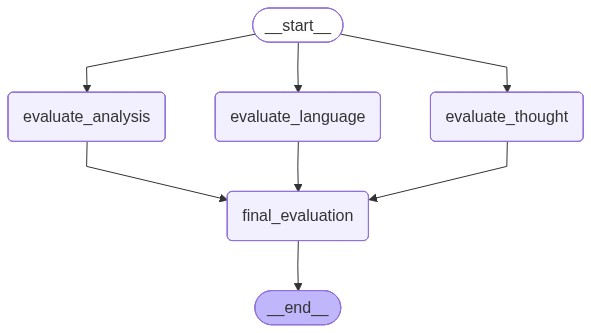

In [11]:
## Visualize Out Graph 
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

In [12]:
essay = """The United States in the Age of AI: The Infrastructure and Capital Superpower

As the world navigates the maturing landscape of artificial intelligence in 2026, the United States stands as the undisputed epicenter of the AI revolution. Driven by an ecosystem of hyperscalers, massive venture capital, and a fiercely competitive free market, the US has transitioned AI from a phase of speculative experimentation into the fundamental backbone of its digital and physical economy. However, the American approach to AI is no longer just a story of software and algorithms; it has evolved into the most capital-intensive infrastructure buildout in modern history, testing the physical limits of the nation's energy grid and resources.

The defining characteristic of the US AI strategy is its sheer scale and rapid commercialization. Silicon Valley and major tech hubs have pioneered the shift toward "Agentic AI" and "Physical AI." Intelligence is no longer confined to chatbots on a screen; autonomous agents are now orchestrating complex, end-to-end enterprise workflows, while advanced robotics powered by massive neural networks are redefining logistics and manufacturing floors. For American corporations, the current era marks a structural reorganization where operating models are being fundamentally redesigned around human-machine collaboration rather than merely automating legacy processes.

Yet, this relentless pursuit of scale has collided with physical reality, triggering an unprecedented energy reckoning. The US is building massive AI data center clusters that require gigawatts of continuous power. With data center electricity consumption projected to more than double in a span of just a few years, the nation is facing a severe power bottleneck. Connecting to the traditional grid now takes years, prompting hyperscalers to pioneer a "Bring Your Own Power" (BYOP) movement. Tech giants are directly funding behind-the-meter gas generation, reviving dormant nuclear facilities, and investing in advanced cooling technologies to fuel their server farms. AI infrastructure has become such a critical priority that it is increasingly viewed through the lens of national security, prompting aggressive federal action to expand the domestic supply of key electrical grid components.

On the policy front, the US government has dramatically accelerated its embrace of artificial intelligence. Moving away from more cautious regulatory frameworks, the focus has shifted entirely to removing barriers to innovation and ensuring tech sovereignty. The goal is clear: maintain a decisive strategic edge over global competitors, particularly China. Federal AI spending has skyrocketed into the tens of billions, dominated overwhelmingly by the Department of Defense, which views AI supremacy as a non-negotiable imperative for future military readiness, cybersecurity, and global diplomacy.

However, this hyper-accelerated growth is not without domestic friction. At the local level, the proliferation of massive data centers is creating tension in communities grappling with the environmental footprint of these facilities. Concerns over local electricity rate hikes, immense water usage in water-stressed regions, and the strain on existing utilities highlight the localized costs of a global tech race. Furthermore, while the US excels at rapid technological deployment, the corporate sector is experiencing a deep divide between companies effectively restructuring for an AI-native future and those struggling with high failure rates due to poor data quality and broken processes.

In conclusion, the United States in the age of AI represents a high-stakes, capital-fueled engine of exponential growth. It is a nation betting that its unmatched capacity for private investment, hardware innovation, and sheer ambition can overcome formidable physical bottlenecks. The American trajectory will ultimately determine whether a market-driven society can build and sustain the colossal physical infrastructure required to unlock the next frontier of human intelligence."""

In [13]:
initial_state = {
    "essay": essay
}

result = workflow.invoke(initial_state)

print(result["overall_feedback"])
print("Average Score:", result["avg_score"])

**Final Summary**

**Overall Assessment**  
The essay is a well‑crafted, policy‑oriented overview that convincingly argues the United States’ position as the pre‑eminent AI superpower in 2026. Its clear structure, sophisticated diction, and logical progression give it a strong foundation, earning it an **overall rating of ~7 / 10** (mid‑point between the three individual scores). To move from competent to exemplary, the piece needs tighter prose, richer evidence, and deeper analytical rigor.

---

### 1. Language & Style (Score ≈ 8/10)

| **Strengths** | **Opportunities for Improvement** |
|---------------|------------------------------------|
| • Cohesive introduction‑body‑conclusion flow. <br>• Appropriate policy‑level terminology (“hyperscalers,” “Agentic AI,” “Bring‑Your‑Own‑Power”). <br>• Varied sentence length that creates a natural rhythm. | • Break overly long sentences (e.g., the 45‑word sentence in paragraph 3) to avoid reader fatigue. <br>• Eliminate redundant phrasing (“und